# Active subspaces of the OpenAeroStruct wing (psdr benchmark)

**Paper:** John P. Jasa¹, John T. Hwang², Joaquim R. R. A. Martins¹, "Open-source coupled aerostructural optimization using Python", *Structural and Multidisciplinary Optimization* 57:1815–1827, 2018.

¹ Department of Aerospace Engineering, University of Michigan, Ann Arbor, MI, USA
² Peerless Technologies Corporation (contractor at NASA Glenn Research Center), Cleveland, OH, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

OpenAeroStruct couples a vortex-lattice aerodynamic model with a 6-DOF spatial-beam spar and computes fuel burn from the Breguet range equation; J. Hokanson's psdr package turned it into a 12-input test function (twist, spar thickness, root chord, taper, angle of attack, and three spar material constants). We rebuilt that test function on the maintained OpenAeroStruct 2.12 and computed 2000 Monte Carlo samples on psdr's design box with OpenMDAO total-derivative gradients. Much of the box describes wings that would not be built: in 1195 of the 2000 samples the spar is over its allowable stress, and the thinnest root spars bring the wing close to static divergence. The analysis keeps the 805 wings whose spar is within the allowable stress (failure ≤ 0, the paper's structural constraint); the files keep every row. On these plausible wings fuel burn has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 49.1$, between 46.1 and 56.7 over four independent draws), set by the angle of attack, the root chord, the twist and the taper, the inputs that fix the lift coefficient and the wing area; the spar thicknesses and the material constants hardly matter. Over the whole box the picture is different and depends on the draw: a few near-divergent samples dominate the gradients and give a two-dimensional subspace led by the root spar thickness (last section).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 2018                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
NAMES = ['twist_1', 'twist_2', 'twist_3', 'thickness_1', 'thickness_2', 'thickness_3',
         'root_chord', 'taper_ratio', 'alpha', 'E', 'G', 'mrho']
labels = [r'$\theta_1$', r'$\theta_2$', r'$\theta_3$', r'$t_1$', r'$t_2$', r'$t_3$', r'$c_r$',
          r'$\lambda$', r'$\alpha$', r'$E$', r'$G$', r'$\rho_m$']

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ normalized inputs $\mathbf{x}\in[-1,1]^m$ with density $\rho$, the matrix $\mathbf{C} = \int \nabla f\,\nabla f^\top \rho\, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$ measures how $f$ changes on average along each direction. When the first $n$ eigenvalues are much larger than the rest, $f$ is nearly a function of the $n$ active variables $\mathbf{y} = \mathbf{W}_1^\top\mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$ shows. $\mathbf{C}$ is estimated by Monte Carlo from sampled gradients, and the bootstrap gives intervals for the eigenvalues and the subspace. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, https://doi.org/10.1137/1.9781611973860.

## The model

**OpenAeroStruct** (paper Sec. 2) models a lifting surface by a vortex-lattice method (VLM) and its spar by 1-D finite elements. The VLM solves $\mathbf{A}\boldsymbol{\Gamma} = -\mathbf{V}_\infty\cdot\mathbf{n}$ for the horseshoe-vortex circulations and gets panel forces $\mathbf{F}_i = \rho\,\Gamma_i(\mathbf{V}_\infty + \mathbf{v}_i)\times\mathbf{l}_i$ (Sec. 2.2). The spar is a chain of spatial beam elements with axial ($EA/L$), bending ($EI/L^3$) and torsional ($GJ/L$) stiffness, so $\mathbf{K}\mathbf{u} = \mathbf{f}$ (Sec. 2.3). Here the spar is a thin-walled tube. Forces go from the aerodynamic mesh to the beam nodes and displacements come back to deform the mesh, and the coupled system is solved to a fixed point (Sec. 3). Fuel burn comes from the Breguet range equation (Sec. 3.4, p. 1823),

$$W_f = (W_0 + W_s)\left[\exp\!\left(\frac{R\cdot \mathrm{SFC}}{V}\left(\frac{L}{D}\right)^{-1}\right) - 1\right],$$

and the paper's structural constraint (Table 1, p. 1826) bounds the Kreisselmeier–Steinhauser (KS) aggregate of the spar's von Mises stresses at a 2.5 g load by the yield stress. OpenAeroStruct evaluates it as the KS aggregate of the stresses at the analysed lift divided by yield/2.5, minus 1 (the 2.5 g sizing load turned into an allowable stress); a value above 0 means the spar fails.

**The parameter study is not in the paper.** It is psdr's `OpenAeroStruct` test function (J. Hokanson, `psdr/demos/oas.py` and `psdr/demos/oas/oas_driver.py`). psdr runs OpenAeroStruct v1 (OpenMDAO 1, Python 2) inside a Docker image; `oas_wing_driver.py` rebuilds the same setup on the maintained OpenAeroStruct 2.12 (OpenMDAO 3.45). Its design inputs are the variables of the paper's Table 1 (thickness, twist, $\alpha$, root chord, taper), and psdr adds the three spar material constants. The setup is a rectangular wing of span 10 m and base chord 1 m, one chordwise panel, 3 spanwise panels on the symmetric half, a tube spar at 35 % chord with outer radius fixed at 0.06 m, inviscid drag only, $M = 0.84$, $\rho_\infty = 0.38$ kg/m³, $R = 11{,}165$ km, $W_0 = 1000$ kg, and the allowable stress yield/2.5 with yield 500 MPa. `DATA.md` lists every reconstruction choice. At psdr's 10 stored test points, the rebuild matches fuel burn and lift to 0.4 % and the spar weight exactly, and its failure value is 0.07–0.14 lower, because OpenAeroStruct 2.x transfers aerodynamic moments to the beam differently from v1. Swapping v1's load transfer into the rebuild reproduces psdr's 10 stored outputs: lift to 1.9e-8, failure to 4.2e-7 and fuel burn to 8.2e-5 (`check_accuracy.py`, check 7). Over the whole design the difference is larger, because it grows on the thin-root-spar samples: across the 2000 samples, fuel burn differs from the v1-transfer value by a median of 0.14 % and at most 13.0 %, and failure by 0.023–1.86; on the 805 plausible wings analysed below, fuel burn differs by a median of 0.08 % and at most 0.30 % (`check_accuracy.py`, check 8). The lift is not trimmed to the weight, as in psdr.

The inputs are independent and uniform. The table below is printed from the ranges used by `generate_data.py`. The control points run from tip to root, using the v1 B-spline convention:

In [2]:
LOWER = np.array([-1, -1, -1, 0.005, 0.005, 0.005, 0.7, 0.75, 2.0, 0.8 * 70e9, 0.8 * 30e9, 0.8 * 3e3])
UPPER = np.array([1, 1, 1, 0.05, 0.05, 0.05, 1.3, 1.25, 5.0, 1.2 * 70e9, 1.2 * 30e9, 1.2 * 3e3])
UNITS = ['deg'] * 3 + ['m'] * 3 + ['-', '-', 'deg', 'Pa', 'Pa', 'kg/m^3']
DESC = ['twist control point 1 (tip)', 'twist control point 2', 'twist control point 3 (root)',
        'spar thickness control point 1 (tip)', 'spar thickness control point 2',
        'spar thickness control point 3 (root)', 'root chord (multiple of 1 m)', 'taper ratio (tip/root chord)',
        'angle of attack', "spar Young's modulus", 'spar shear modulus', 'spar material density']
print(f"{'input':12s} {'units':7s} {'lower':>10s} {'upper':>10s}  description")
for n, u, lo, up, d in zip(NAMES, UNITS, LOWER, UPPER, DESC):
    print(f'{n:12s} {u:7s} {lo:10.4g} {up:10.4g}  {d}')

input        units        lower      upper  description
twist_1      deg             -1          1  twist control point 1 (tip)
twist_2      deg             -1          1  twist control point 2
twist_3      deg             -1          1  twist control point 3 (root)
thickness_1  m            0.005       0.05  spar thickness control point 1 (tip)
thickness_2  m            0.005       0.05  spar thickness control point 2
thickness_3  m            0.005       0.05  spar thickness control point 3 (root)
root_chord   -              0.7        1.3  root chord (multiple of 1 m)
taper_ratio  -             0.75       1.25  taper ratio (tip/root chord)
alpha        deg              2          5  angle of attack
E            Pa         5.6e+10    8.4e+10  spar Young's modulus
G            Pa         2.4e+10    3.6e+10  spar shear modulus
mrho         kg/m^3        2400       3600  spar material density


**Quantities of interest** (psdr's five outputs, in psdr's order; psdr gave the two weights in N): fuel burn $W_f$ (kg), spar mass (kg), lift $L$ (N), total mass $W_0 + W_s + W_f$ (kg), and failure (KS, dimensionless). The main QoI here is fuel burn, and failure is the second.

**Gradients** are in physical units. They come from OpenMDAO total derivatives (a direct linear solve of the coupled system) for the 9 geometric and flight inputs, and from central differences for $E$ and $G$, which are OpenAeroStruct options rather than variables. The derivative with respect to density is exact, because the spar mass is linear in it. They agree with independent central differences of the whole model to a relative $7.2\times10^{-9}$ or better at the six samples checked (`check_accuracy.py`, check 1).

## Load the data

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                          # (M, 12) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')                         # (M, 5) fuelburn, mass, lift, total mass, failure
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 5, 12)    # (M, 5, 12) physical gradients
QOIS = ['fuel burn (kg)', 'spar mass (kg)', 'lift (N)', 'total mass (kg)', 'failure (KS)']
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')
print(f'fuel burn: range [{F[:, 0].min():.1f}, {F[:, 0].max():.1f}] kg, mean {F[:, 0].mean():.1f} kg; '
      f'failure > 0 (spar over the allowable stress) at {np.sum(F[:, 4] > 0)} of {len(F)} samples')
LW = F[:, 2] / (9.80665 * F[:, 3])
print(f'lift / weight: range [{LW.min():.2f}, {LW.max():.2f}] (analysis only, not trimmed); '
      f'samples with L < W: {np.sum(LW < 1)}')

inputs (2000, 12), outputs (2000, 5), gradients (2000, 5, 12)
fuel burn: range [28.2, 261.8] kg, mean 98.8 kg; failure > 0 (spar over the allowable stress) at 1195 of 2000 samples
lift / weight: range [0.89, 7.63] (analysis only, not trimmed); samples with L < W: 1


## Plausible wings

psdr's box contains many wings that would not be built. Fuel burn is psdr's untrimmed output (the lift is not trimmed to the weight; lift/weight runs from 0.89 to 7.63), and failure is OpenAeroStruct's stress measure at the analysed lift: in 1195 of the 2000 samples the spar is over its allowable stress. The samples with the thinnest root spars are close to static divergence: the spar at 35 % chord sits behind the aerodynamic center at 25 %, so lift twists the wing nose-up, and a soft spar lets it twist further. At the in-box corner with every thickness 5 mm, $c_r = 1.3$, taper 1.25, $\alpha = 5°$, twist $+1°$ and the minimum $E$ and $G$, the model gives a fuel burn of 843 kg, a lift of 330 kN (17.7 times the weight) and failure 25.8 (`check_accuracy.py`, check 6). These are converged analyses, not model errors, but such wings say little about a design study.

**Rule.** The analysis keeps the samples whose spar is within the allowable stress, failure ≤ 0, and drops the others; `outputs.csv` keeps every row. The rule is the paper's own structural constraint (Table 1, p. 1826), which any design would have to meet; it uses only a stored output; and it removes the near-divergent wings, whose stresses are far above the allowable. Two caveats. The failure value is OpenAeroStruct 2.12's, which differs from psdr's (v1 load transfer): with v1's transfer the rule would keep 645 rows instead of 805 (`check_accuracy.py`, check 8). And the lift stays untrimmed: a cruise condition $L \approx W$ would keep only a few dozen rows (37 have lift/weight ≤ 1.5), so it is not used; on the kept rows lift/weight is at most 3.47 (printed below).

In [4]:
keep = F[:, 4] <= 0                                   # the rule: the spar is within the allowable stress
Gn_all = G[:, 0] * (UPPER - LOWER) / 2                # normalized fuel-burn gradients, all rows
g2_all = np.sum(Gn_all**2, axis=1)
print(f'rule failure <= 0 keeps {keep.sum()} of {len(keep)} rows and drops {np.sum(~keep)}')
print(f'kept rows: lift / weight {LW[keep].min():.2f} to {LW[keep].max():.2f} (all rows {LW.min():.2f} to {LW.max():.2f}); '
      f'root thickness from {1e3 * X[keep, 5].min():.1f} mm (all rows {1e3 * X[:, 5].min():.1f} mm); '
      f'fuel burn up to {F[keep, 0].max():.1f} kg (all rows {F[:, 0].max():.1f} kg)')
print(f'the dropped rows hold {g2_all[~keep].sum() / g2_all.sum():.1%} of the trace of C for fuel burn over all rows')
for a, b in ((5, 10), (10, 20), (20, 30), (30, 50)):
    m = (X[:, 5] >= a / 1e3) & (X[:, 5] < b / 1e3)
    print(f'root thickness {a:2d}-{b:2d} mm: {m.sum():4d} rows, {keep[m].mean():4.0%} kept')
Xa, Fa, Ga = X, F, G                                  # all 2000 rows, used again in the last section
X, F, G = X[keep], F[keep], G[keep]                   # from here on: the kept rows
fb, fail = F[:, 0], F[:, 4]
M = len(X)

rule failure <= 0 keeps 805 of 2000 rows and drops 1195
kept rows: lift / weight 0.89 to 3.47 (all rows 0.89 to 7.63); root thickness from 8.2 mm (all rows 5.0 mm); fuel burn up to 111.1 kg (all rows 261.8 kg)
the dropped rows hold 84.2% of the trace of C for fuel burn over all rows
root thickness  5-10 mm:  201 rows,   1% kept
root thickness 10-20 mm:  409 rows,  20% kept
root thickness 20-30 mm:  456 rows,  40% kept
root thickness 30-50 mm:  934 rows,  58% kept


## Estimate the subspace

From here on the analysis uses the 805 kept rows; the last section repeats the main steps on all 2000 rows. The kept rows are a sample of the uniform density restricted to the region failure ≤ 0, so $\mathbf{C}$ is the average of $\nabla f\,\nabla f^\top$ over the plausible part of the box; the inputs are still normalized by psdr's box. The gradients are exact to the solver tolerance, so we use the gradient estimator (`estimator='as'`) with 500 bootstrap replicates; 805 samples are 67 per input.

**Dimension.** $n = 1$. Both versions of the eigenvalue-gap rule (`evg`, linear and log gap) pick it: $\lambda_1/\lambda_2 = 49.1$ is by far the largest ratio ($\lambda_2/\lambda_3 = 6.2$; printed below), its bootstrap interval is [45.2, 53.5], it stays between 46.1 and 56.7 over four independent draws, and the bootstrap distance of $\mathbf{w}_1$ is 0.005 (sections below). A second active variable improves a polynomial surrogate (surrogate section); that is reported but does not change the choice. The smallest eigenvalue, $\lambda_{12} = 3.5\times10^{-8}\lambda_1$, belongs to a physical near-invariance, not rounding: $\mathbf{w}_{12}$ is a uniform twist offset traded against the angle of attack, almost exactly the direction $(1, 1, 1, -2/3)$ on (twist_1..3, $\alpha$) in normalized units (overlap 0.979). The sign of $\mathbf{w}_1$ makes fuel burn increase along it (`ac.orient`, by covariance); the paper has no figure to follow.

In [5]:
space = ac.Uniform(LOWER, UPPER, names=NAMES)
sub0 = ac.active_subspace(space=space, X=X, f=fb, grads=G[:, 0], estimator='as', dimension_rule='evg',
                          nboot=500, rng=SEED)
sub = ac.orient(sub0, by='covariance', X=X, f=fb, columns=2)
lam = sub.eigenvalues
_, _, n_log = ac.dimension_criterion(sub, rule=ac.subspaces.EVG(gap='log'))
print('eigenvalues:', np.array2string(lam, precision=3))
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}, '
      f'lambda_3/lambda_4 = {lam[2] / lam[3]:.1f}; lambda_11/lambda_12 = {lam[10] / lam[11]:.0f}')
print(f'evg (linear gap) picks n = {sub.n}; evg (log gap) picks n = {n_log}')
print(f'share of sum(lambda) in the first: {lam[0] / lam.sum():.4f}')
# the last direction: a uniform twist offset of d deg against an angle-of-attack change of -d deg is
# nearly invariant; in normalized units (half-ranges 1 deg and 1.5 deg) that is (1, 1, 1, -2/3) on (twist_1..3, alpha)
d12 = np.zeros(12); d12[[0, 1, 2]] = 1.0; d12[8] = -2 / 3; d12 /= np.linalg.norm(d12)
print(f'lambda_12 / lambda_1 = {lam[11] / lam[0]:.1e}; |w12 . (1, 1, 1, -2/3)/norm| = {abs(sub.W[:, 11] @ d12):.3f}')

eigenvalues: [2.395e+03 4.878e+01 7.810e+00 2.651e+00 1.248e+00 9.125e-01 3.122e-01
 1.236e-01 7.064e-02 4.578e-02 1.800e-03 8.333e-05]
lambda_1/lambda_2 = 49.1, lambda_2/lambda_3 = 6.2, lambda_3/lambda_4 = 2.9; lambda_11/lambda_12 = 22
evg (linear gap) picks n = 1; evg (log gap) picks n = 1
share of sum(lambda) in the first: 0.9748
lambda_12 / lambda_1 = 3.5e-08; |w12 . (1, 1, 1, -2/3)/norm| = 0.979


## Results

### Eigenvalues

bootstrap 95% intervals, lambda_1..3: [2.35e+03, 2.45e+03], [44.6, 53], [7.13, 8.5]
bootstrap 95% intervals of the ratios: lambda_1/lambda_2 [45.2, 53.5], lambda_2/lambda_3 [5.5, 7.2]
the 1 largest samples (0.1%) hold 0.3% of trace(C)
the 8 largest samples (1.0%) hold 2.0% of trace(C)
the 40 largest samples (5.0%) hold 8.7% of trace(C)


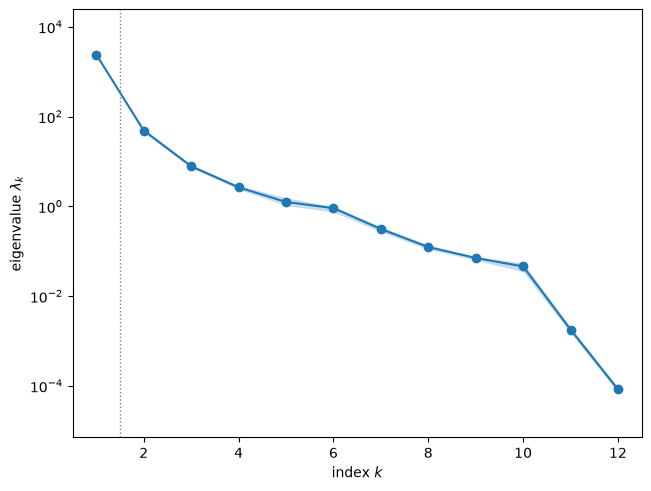

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('bootstrap 95% intervals, lambda_1..3:', ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo[:3], hi[:3])))
bl = sub.bootstrap_eigenvalues
q12 = np.percentile(bl[:, 0] / bl[:, 1], [2.5, 97.5])
q23 = np.percentile(bl[:, 1] / bl[:, 2], [2.5, 97.5])
print(f'bootstrap 95% intervals of the ratios: lambda_1/lambda_2 [{q12[0]:.1f}, {q12[1]:.1f}], '
      f'lambda_2/lambda_3 [{q23[0]:.1f}, {q23[1]:.1f}]')
Gn = G[:, 0] * (UPPER - LOWER) / 2                    # normalized gradients of fuel burn, kept rows
g2 = np.sum(Gn**2, axis=1)                            # their squared norms; sum(g2)/M = trace(C)
order = np.argsort(-g2)
for k in (1, M // 100, M // 20):
    print(f'the {k} largest samples ({k / M:.1%}) hold {g2[order[:k]].sum() / g2.sum():.1%} of trace(C)')
fig

$\lambda_1 = 2.39\times10^3$ holds 97.5 % of the sum; $\lambda_2 = 48.8$ and $\lambda_3 = 7.8$. The bootstrap 95 % intervals are [2.35e3, 2.45e3] for $\lambda_1$, [44.6, 53] for $\lambda_2$, [7.13, 8.5] for $\lambda_3$, and [45.2, 53.5] for $\lambda_1/\lambda_2$. On the kept rows the gradients are not heavy-tailed: the single largest sample holds 0.3 % of trace($\mathbf{C}$), the largest 1 % of the samples hold 2.0 % and the largest 5 % hold 8.7 %, so the bootstrap intervals can be read at face value.

### How much do the eigenvalues depend on the draw?

The 2000 rows are independent Monte Carlo samples, so the kept rows of each block of 500 file rows are an independent draw from the plausible region (194 to 219 rows each), and the two halves are two draws of about 400. For each we print the leading eigenvalues, the ratios, the distance between its $\mathbf{w}_1$ and that of all kept rows, and the share of the trace held by its largest 5 % of samples.

In [7]:
def eig_C(rows):
    C = Gn[rows].T @ Gn[rows] / len(rows)
    l, V = np.linalg.eigh(C)
    return l[::-1], V[:, ::-1]


def dist(A, B):                                       # distance between the spans of A and B (2-norm)
    return np.linalg.norm(A @ A.T - B @ B.T, 2)


W = sub.W
idx = np.flatnonzero(keep)                            # row numbers (in the files) of the kept rows
print(f"{'file rows':>11s} {'kept':>5s} {'lambda_1':>9s} {'lambda_2':>9s} {'lambda_3':>9s} {'l1/l2':>6s} {'l2/l3':>6s}"
      f" {'dist w1':>8s} {'top 5% share':>12s}")
blocks = [(a, a + 500) for a in range(0, 2000, 500)] + [(0, 1000), (1000, 2000)]
R12 = []
for a, b in blocks:
    r = np.flatnonzero((idx >= a) & (idx < b))
    l, V = eig_C(r)
    s5 = np.sort(g2[r])[::-1][:len(r) // 20].sum() / g2[r].sum()
    if b - a == 500:
        R12.append(l[0] / l[1])
    print(f'{a:5d}:{b:<5d} {len(r):5d} {l[0]:9.0f} {l[1]:9.1f} {l[2]:9.1f} {l[0] / l[1]:6.1f} {l[1] / l[2]:6.1f}'
          f' {dist(V[:, :1], W[:, :1]):8.3f} {s5:12.1%}')
print(f'over the {len(R12)} disjoint draws: lambda_1/lambda_2 from {min(R12):.1f} to {max(R12):.1f}')

  file rows  kept  lambda_1  lambda_2  lambda_3  l1/l2  l2/l3  dist w1 top 5% share
    0:500     194      2424      42.8       7.5   56.7    5.7    0.005         8.2%
  500:1000    194      2441      51.1       7.8   47.8    6.5    0.004         8.5%
 1000:1500    198      2366      50.0       7.4   47.3    6.7    0.006         7.7%
 1500:2000    219      2354      51.0       8.3   46.1    6.1    0.005         7.7%
    0:1000    388      2433      46.9       7.7   51.9    6.1    0.003         8.8%
 1000:2000    417      2360      50.6       7.9   46.7    6.4    0.002         8.1%
over the 4 disjoint draws: lambda_1/lambda_2 from 46.1 to 56.7


Across the four independent draws, $\lambda_1/\lambda_2$ ranges from 46.1 to 56.7 and $\lambda_2/\lambda_3$ from 5.7 to 6.7, and every block's $\mathbf{w}_1$ lies within 0.006 of the full one. An independent 400-sample design (`default_rng(99)`, not shipped) gives $\lambda_1/\lambda_2 = 45.7$ on its 154 rows with failure ≤ 0 (`check_accuracy.py`, check 9). So the one-dimensional subspace and its gap are stable from draw to draw, unlike those of the whole box (last section).

### Subspace errors

bootstrap mean subspace distance, k = 1..5: [0.005 0.018 0.038 0.063 0.19 ]


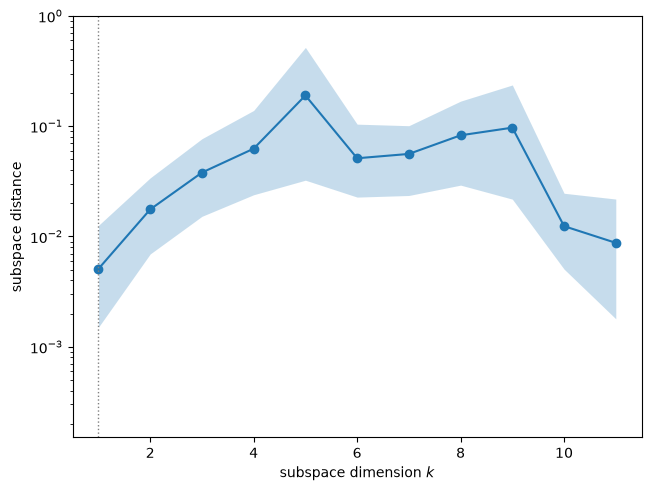

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
bd = sub.bootstrap_distances.mean(axis=0)
print('bootstrap mean subspace distance, k = 1..5:', np.array2string(bd[:5], precision=3))
fig

The bootstrap mean distance is 0.005 for the one-dimensional subspace, 0.018 for $k = 2$ and 0.038 for $k = 3$: $\mathbf{w}_1$ is well determined.

### Eigenvectors

w1: twist_1 +0.246, twist_2 +0.154, twist_3 +0.128, thickness_1 +0.057, thickness_2 +0.018, thickness_3 +0.029, root_chord +0.466, taper_ratio +0.210, alpha +0.793, E -0.002, G -0.032, mrho +0.059
w2: twist_1 -0.121, twist_2 -0.102, twist_3 -0.096, thickness_1 +0.072, thickness_2 +0.030, thickness_3 +0.085, root_chord +0.812, taper_ratio +0.242, alpha -0.480, E -0.004, G +0.036, mrho +0.052
weight of the planform and flight inputs (twist, root chord, taper, alpha) in w1: 0.991; of the three thicknesses: 0.0045; of E, G, density: 0.0045


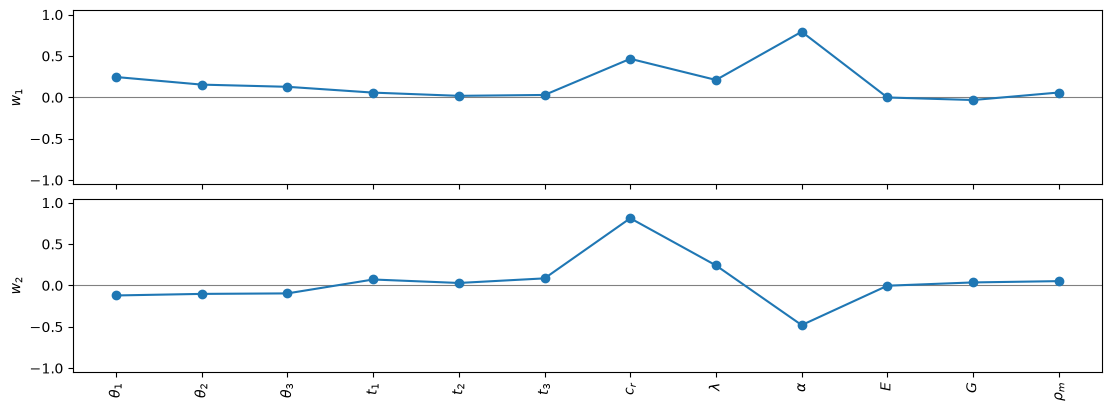

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
for j in range(2):
    print(f'w{j + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(NAMES, W[:, j])))
aero = [0, 1, 2, 6, 7, 8]                             # twist_1..3, root_chord, taper_ratio, alpha
print(f'weight of the planform and flight inputs (twist, root chord, taper, alpha) in w1: '
      f'{np.sum(W[aero, 0]**2):.3f}; of the three thicknesses: {np.sum(W[3:6, 0]**2):.4f}; '
      f'of E, G, density: {np.sum(W[9:, 0]**2):.4f}')
fig

$\mathbf{w}_1$ is led by the angle of attack ($+0.793$) and the root chord ($+0.466$), followed by the twist control points ($+0.246$ at the tip, $+0.154$, $+0.128$ at the root) and the taper ratio ($+0.210$). These six inputs carry 0.991 of its squared length; the three spar thicknesses carry 0.0045 and $E$, $G$ and the density 0.0045. This is the aerodynamics of an inviscid wing: with no viscous or wave drag, $C_D/C_L$ is the induced-drag ratio $C_L/(\pi e\,AR)$, which grows with the lift coefficient (angle of attack and twist) and with the wing area at fixed span (root chord and taper, which lower the aspect ratio), and the Breguet fuel burn grows with $C_D/C_L$. On wings whose spar carries its load, the structure enters only through the small spar mass in the Breguet weight. $\mathbf{w}_2$ (root chord $+0.812$, $\alpha$ $-0.480$) holds $\lambda_2 = 48.8$.

### Sufficient summary plots

y1 range [-1.54, 0.30]; corr(fb, y1) = 0.982


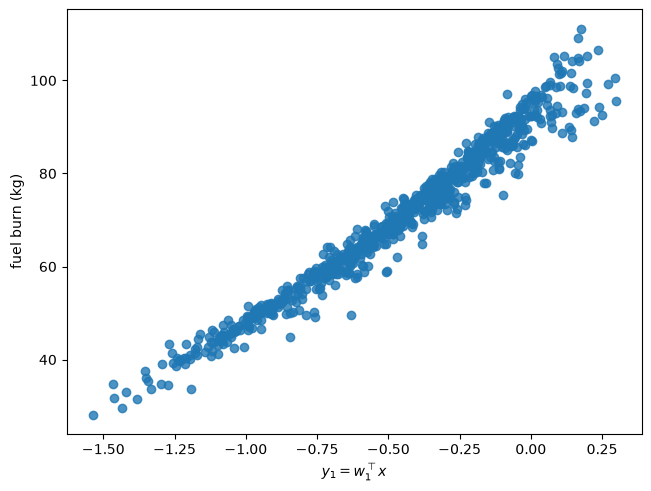

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=fb, dims=1, qoi_label='fuel burn (kg)')
plt.close(fig)
Y = space.to_normalized(X) @ W[:, :2]
print(f'y1 range [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(fb, y1) = {np.corrcoef(fb, Y[:, 0])[0, 1]:.3f}')
fig

y2 range [-1.39, 1.54]; corr(fb, y2) = 0.029


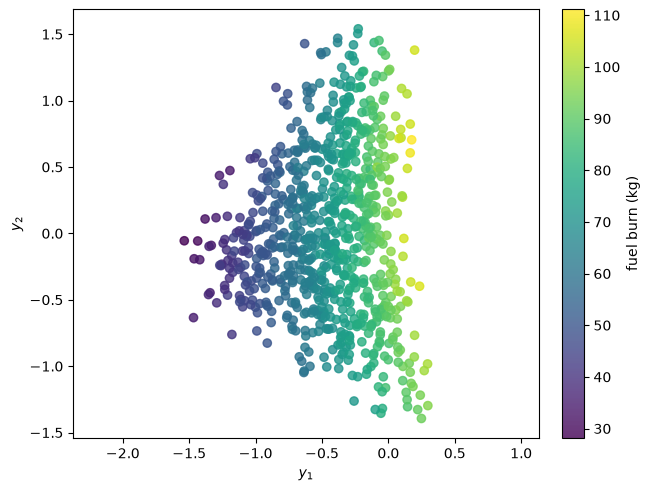

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=fb, dims=2, qoi_label='fuel burn (kg)')
plt.close(fig)
print(f'y2 range [{Y[:, 1].min():.2f}, {Y[:, 1].max():.2f}]; corr(fb, y2) = {np.corrcoef(fb, Y[:, 1])[0, 1]:.3f}')
fig

Against $y_1$ alone fuel burn lies close to one curve (correlation 0.982), from 28.2 to 111.1 kg. The kept rows cover $y_1$ from $-1.54$ to $0.30$ only: the rule removes the high-lift end of $\mathbf{w}_1$ (large $\alpha$ and root chord), where the spar is overloaded. In the $(y_1, y_2)$ plane the color changes mostly along $y_1$; the correlation with $y_2$ is 0.029. "Fuel burn" here is psdr's output: the Breguet formula evaluated with the $C_D/C_L$ of the wing at the given $\alpha$, with the lift not trimmed to the weight (lift/weight 0.89–3.47 on the kept rows). It is a function of the drag-to-lift ratio at that angle of attack, not the fuel burn of a mission.

### Surrogate on the active variables

Polynomials in one and two active variables, scored by leave-one-out (LOO) $R^2$ on the 805 kept rows:

n = 1, degree 1: LOO R^2 = 0.9631
n = 1, degree 2: LOO R^2 = 0.9659
n = 1, degree 3: LOO R^2 = 0.9666
n = 2, degree 1: LOO R^2 = 0.9632
n = 2, degree 2: LOO R^2 = 0.9940
n = 2, degree 3: LOO R^2 = 0.9941


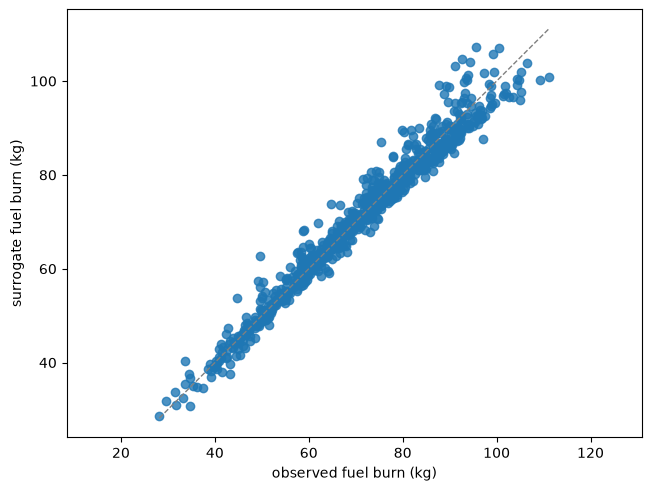

In [12]:
r2 = {}
for n in (1, 2):
    for d in (1, 2, 3):
        r2[(n, d)] = ac.fit_surrogate(X=X, f=fb, space=space, subspace=ac.with_dimension(sub, n), kind='poly',
                                      degree=d).loo_r_squared
for (n, d), v in sorted(r2.items()):
    print(f'n = {n}, degree {d}: LOO R^2 = {v:.4f}')
sur = ac.fit_surrogate(X=X, f=fb, space=space, subspace=sub, kind='poly', degree=2)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X, f=fb, qoi_label='fuel burn (kg)')
plt.close(fig)
fig

A quadratic in $y_1$ alone has LOO $R^2 = 0.966$ (a straight line 0.963, a cubic 0.967). Adding $y_2$ raises the quadratic to 0.994 (the cubic also 0.994): fuel burn has a weak second direction that a surrogate can use, although its eigenvalue is 49 times smaller than $\lambda_1$. The plot shows the quadratic in $y_1$.

### The other outputs

The same estimator applied to psdr's other four outputs on the kept rows, each with its own gradients (no bootstrap):

In [13]:
print(f"{'QoI':16s} {'l1/l2':>8s} {'l2/l3':>8s}  largest |w1| components")
subs = {}
for i, q in enumerate(QOIS):
    s = ac.active_subspace(space=space, X=X, f=F[:, i], grads=G[:, i], estimator='as', n=1)
    subs[i] = s
    l = s.eigenvalues
    top = np.argsort(-np.abs(s.W[:, 0]))[:3]
    print(f'{q:16s} {l[0] / l[1]:8.1f} {l[1] / l[2]:8.1f}  ' + ', '.join(f'{NAMES[k]} {s.W[k, 0]:+.2f}' for k in top))
w_fail = subs[4].W[:, 0]
print(f'|w1(fuel burn) . w1(failure)| = {abs(W[:, 0] @ w_fail):.3f}')
# spar mass: which inputs it depends on, and its small eigenvalues
lm, Wm = subs[1].eigenvalues, subs[1].W
Gm = G[:, 1] * (UPPER - LOWER) / 2
print(f'spar mass: largest |d/dE|, |d/dG| over the kept rows: {np.abs(G[:, 1, 9]).max():.1f}, {np.abs(G[:, 1, 10]).max():.1f}')
print('spar mass: largest normalized |gradient| per input: '
      + ', '.join(f'{n} {v:.2g}' for n, v in zip(NAMES, np.abs(Gm).max(axis=0))))
print('spar mass: lambda_k / lambda_1, k = 5..12:', np.array2string(lm[4:] / lm[0], precision=1))
for k in range(4, 8):
    top = np.argsort(-np.abs(Wm[:, k]))[:2]
    print(f'  w{k + 1} led by ' + ', '.join(f'{NAMES[j]} {Wm[j, k]:+.2f}' for j in top))

QoI                 l1/l2    l2/l3  largest |w1| components
fuel burn (kg)       49.1      6.2  alpha +0.79, root_chord +0.47, twist_1 +0.25
spar mass (kg)       25.0      1.5  thickness_1 +0.64, thickness_3 +0.52, mrho +0.51
lift (N)             48.6     22.4  alpha +0.81, root_chord +0.47, twist_3 +0.19
total mass (kg)      27.0      1.8  thickness_1 +0.57, mrho +0.47, thickness_3 +0.46
failure (KS)          6.6      9.2  alpha +0.72, thickness_3 -0.44, root_chord +0.41
|w1(fuel burn) . w1(failure)| = 0.880
spar mass: largest |d/dE|, |d/dG| over the kept rows: 0.0, 0.0
spar mass: largest normalized |gradient| per input: twist_1 0.00017, twist_2 9.4e-05, twist_3 0.00013, thickness_1 1.1e+02, thickness_2 39, thickness_3 1e+02, root_chord 0.0026, taper_ratio 0.012, alpha 0, E 0, G 0, mrho 66
spar mass: lambda_k / lambda_1, k = 5..12: [1.3e-09 3.2e-11 1.5e-13 9.4e-14 7.1e-37 0.0e+00 0.0e+00 0.0e+00]
  w5 led by taper_ratio +1.00, root_chord -0.03
  w6 led by root_chord +1.00, taper_ratio

failure: LOO R^2 cubic in w1 0.862, cubic in (w1, w2) 0.966
failure range on the kept rows [-0.69, -0.00]


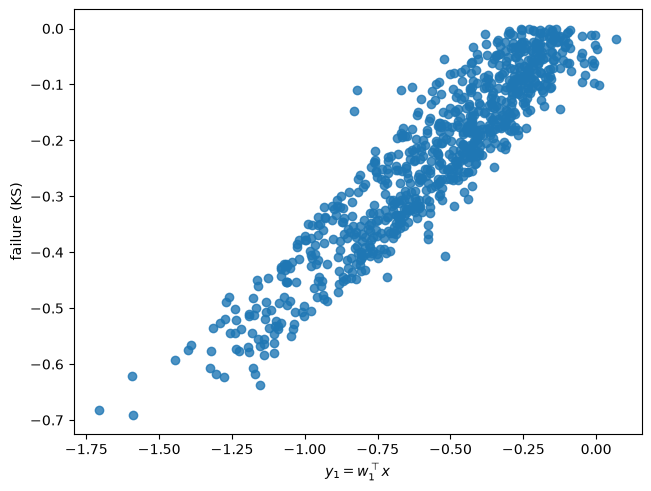

In [14]:
fig, ax = ac.plotting.plot_sufficient_summary(subs[4], X=X, f=fail, dims=1, qoi_label='failure (KS)')
plt.close(fig)
sf2 = ac.active_subspace(space=space, X=X, f=fail, grads=G[:, 4], estimator='as', n=2)
print(f'failure: LOO R^2 cubic in w1 {ac.fit_surrogate(X=X, f=fail, space=space, subspace=subs[4], kind="poly", degree=3).loo_r_squared:.3f}, '
      f'cubic in (w1, w2) {ac.fit_surrogate(X=X, f=fail, space=space, subspace=sf2, kind="poly", degree=3).loo_r_squared:.3f}')
print(f'failure range on the kept rows [{fail.min():.2f}, {fail.max():.2f}]')
fig

Lift has nearly the same leading direction as fuel burn ($\lambda_1/\lambda_2 = 48.6$; $\alpha$ $+0.81$, root chord $+0.47$): on the kept rows fuel burn follows how much lift the wing makes. The spar mass depends on the three thickness control points and the density ($\lambda_1/\lambda_2 = 25.0$, $\lambda_2/\lambda_3 = 1.5$). Its derivatives with respect to $E$, $G$ and $\alpha$ are exactly 0, and it depends only weakly on the geometry: the spar runs at 35 % chord, so its length changes slightly with the chord, the taper and the twist (largest normalized derivatives 0.012 for taper and 0.0026 for root chord, against about 100 for the thicknesses). That weak dependence gives eigenvalues 5–8 ($1.3\times10^{-9}$ to about $10^{-13}$ times $\lambda_1$; $\mathbf{w}_5$ is the taper axis, $\mathbf{w}_6$ the root chord, $\mathbf{w}_7$ and $\mathbf{w}_8$ twist combinations); eigenvalues 9–12 are zero to rounding. Total mass (spar mass plus fuel burn plus $W_0$) mixes the two ($\lambda_1/\lambda_2 = 27.0$, $\lambda_2/\lambda_3 = 1.8$). The signs in the table are not oriented.

Failure on the kept rows (from $-0.69$ to 0) has its own leading direction, $\alpha$ ($+0.72$), root thickness ($-0.44$) and root chord ($+0.41$): more lift and a thinner root spar raise the stress. Its $\lambda_1/\lambda_2$ is 6.6, a cubic in one active variable reaches LOO $R^2 = 0.862$ and a cubic in two 0.966, and its $\mathbf{w}_1$ has $|\cos| = 0.880$ with that of fuel burn. **This failure output is not psdr's.** With OpenAeroStruct 2.x's load transfer it is lower than with v1's (which psdr used) at every sample: by 0.023 to 0.112 (median 0.072) on the kept rows and by 0.023 to 1.86 over all 2000 (`check_accuracy.py`, check 8).

## The whole psdr box (all 2000 rows)

For comparison, the main steps on all 2000 rows, including the 1195 wings with an overloaded spar (fuel burn, $n = 2$, 500 bootstrap replicates):

In [15]:
suba = ac.active_subspace(space=space, X=Xa, f=Fa[:, 0], grads=Ga[:, 0], estimator='as', n=2, nboot=500, rng=SEED)
suba = ac.orient(suba, by='covariance', X=Xa, f=Fa[:, 0], columns=2)
la = suba.eigenvalues
print('all 2000 rows, eigenvalues:', np.array2string(la[:4], precision=3), '...')
print(f'lambda_1/lambda_2 = {la[0] / la[1]:.2f}, lambda_2/lambda_3 = {la[1] / la[2]:.1f}, lambda_3/lambda_4 = {la[2] / la[3]:.1f}')
order_a = np.argsort(-g2_all)
for k in (1, 20, 100):
    print(f'the {k} largest samples hold {g2_all[order_a[:k]].sum() / g2_all.sum():.1%} of trace(C); '
          f'{np.sum(~keep[order_a[:k]])} of them are dropped by the rule')
thin = Xa[:, 5] < 0.0075
print(f'{thin.sum()} rows with root thickness < 7.5 mm hold {g2_all[thin].sum() / g2_all.sum():.1%}; '
      f'the rule keeps {np.sum(keep & thin)} of them')
ra = []
for a in range(0, 2000, 500):
    C = Gn_all[a:a + 500].T @ Gn_all[a:a + 500] / 500
    l = np.linalg.eigvalsh(C)[::-1]
    ra.append((l[0] / l[1], l[1] / l[2]))
ra = np.array(ra)
print(f'four disjoint draws of 500: lambda_1/lambda_2 from {ra[:, 0].min():.2f} to {ra[:, 0].max():.2f}, '
      f'lambda_2/lambda_3 from {ra[:, 1].min():.1f} to {ra[:, 1].max():.1f}')
bda = suba.bootstrap_distances.mean(axis=0)
print(f'bootstrap mean subspace distance, n = 1, 2: {bda[0]:.3f}, {bda[1]:.3f}')
Pa = suba.W[:, :2] @ suba.W[:, :2].T
print('all rows, squared length of each input axis inside the plane:',
      ', '.join(f'{n} {Pa[k, k]:.3f}' for k, n in enumerate(NAMES) if Pa[k, k] > 0.01))
print(f'length of the kept rows\' w1 inside the all-row plane: {np.linalg.norm(suba.W[:, :2].T @ W[:, 0]):.3f}; '
      f'|w1(kept) . w1(all)| = {abs(W[:, 0] @ suba.W[:, 0]):.3f}')
for n in (1, 2):
    v = ac.fit_surrogate(X=Xa, f=Fa[:, 0], space=space, subspace=ac.with_dimension(suba, n), kind='poly',
                         degree=3).loo_r_squared
    print(f'all rows, cubic in {n} active variable(s): LOO R^2 = {v:.4f}')
sfa = ac.active_subspace(space=space, X=Xa, f=Fa[:, 4], grads=Ga[:, 4], estimator='as', n=1)
lf = sfa.eigenvalues
print(f'failure, all rows: lambda_1/lambda_2 = {lf[0] / lf[1]:.1f}; w1 component of thickness_3 {sfa.W[5, 0]:+.2f}, '
      f'largest other |component| {np.max(np.abs(np.delete(sfa.W[:, 0], 5))):.2f}')

all 2000 rows, eigenvalues: [4339.796 1832.839   64.608    7.451] ...
lambda_1/lambda_2 = 2.37, lambda_2/lambda_3 = 28.4, lambda_3/lambda_4 = 8.7
the 1 largest samples hold 6.3% of trace(C); 1 of them are dropped by the rule
the 20 largest samples hold 31.9% of trace(C); 20 of them are dropped by the rule
the 100 largest samples hold 45.3% of trace(C); 100 of them are dropped by the rule
90 rows with root thickness < 7.5 mm hold 39.7%; the rule keeps 0 of them
four disjoint draws of 500: lambda_1/lambda_2 from 2.08 to 4.18, lambda_2/lambda_3 from 13.5 to 42.4
bootstrap mean subspace distance, n = 1, 2: 0.097, 0.010
all rows, squared length of each input axis inside the plane: twist_1 0.055, twist_2 0.021, twist_3 0.013, thickness_3 0.990, root_chord 0.280, taper_ratio 0.065, alpha 0.561
length of the kept rows' w1 inside the all-row plane: 0.996; |w1(kept) . w1(all)| = 0.851
all rows, cubic in 1 active variable(s): LOO R^2 = 0.7785
all rows, cubic in 2 active variable(s): LOO R^2 = 0.9

Over the whole box fuel burn looks different. The leading eigenvalues are $4.34\times10^3$ and $1.83\times10^3$ ($\lambda_1/\lambda_2 = 2.37$, $\lambda_2/\lambda_3 = 28.4$), and the gradients are heavy-tailed: the single largest sample (row 56, root thickness 5.3 mm) holds 6.3 % of trace($\mathbf{C}$), the largest 20 samples hold 31.9 % and the largest 100 hold 45.3 %. The rule drops all of them, and all 90 rows with a root thickness below 7.5 mm, which hold 39.7 %; the dropped rows hold 84.2 % of the trace. These near-divergent wings make the eigenvalues depend on the draw: over the four disjoint blocks of 500 rows, $\lambda_1/\lambda_2$ runs from 2.08 to 4.18 and $\lambda_2/\lambda_3$ from 13.5 to 42.4, and the independent 400-sample design gives 6.4 and 8.6 (`check_accuracy.py`, check 9). Only the plane spanned by $\mathbf{w}_1$ and $\mathbf{w}_2$ is stable (bootstrap distance 0.010 for $n = 2$, 0.097 for $n = 1$), which is why $n = 2$ is used here; a cubic in two active variables reaches LOO $R^2 = 0.984$, in one 0.7785. The root-thickness axis lies almost entirely in that plane (squared length 0.990), followed by $\alpha$ (0.561) and the root chord (0.280). Failure over the whole box is nearly a function of the root thickness alone ($\lambda_1/\lambda_2 = 64.5$, component $+0.99$), so the rule acts mostly as a cut on the root thickness: it keeps 1 % of the rows with a root spar thinner than 10 mm and 58 % of those thicker than 30 mm (rule cell).

**How the headline changes.** On the whole box, fuel burn has a two-dimensional active subspace led by the root spar thickness, the angle of attack and the root chord, with eigenvalues and gap ratios that change from draw to draw. On the plausible wings it has a one-dimensional subspace with a large, stable gap ($\lambda_1/\lambda_2 = 49.1$), set by the angle of attack, the root chord, the twist and the taper; the root spar thickness, the leading input of the whole box, has a component of only 0.029 in it. The plausible $\mathbf{w}_1$ lies inside the whole-box plane (length of its projection 0.996): it is the direction left in that plane once the thin-spar direction is removed.

## Comparison with the paper

The paper is an educational description of the code and has no parameter study, sensitivity analysis or active subspace. The table therefore compares the setup. The numbers in the psdr rows come from `check_accuracy.py` (check 7), not from this notebook.

In [16]:
rows = [
    ('design variables (Table 1, p. 1826)', 'thickness, twist, alpha, root chord, taper', 'the same, 3 control points each for thickness and twist'),
    ('extra inputs', 'not reported (psdr adds E, G, density)', 'E, G, density, U[0.8, 1.2] x nominal'),
    ('fuel burn model', 'Breguet range equation (Sec. 3.4)', 'Breguet, inviscid CD, untrimmed'),
    ('failure model', 'KS of von Mises stress at 2.5 g, Table 1', 'KS (rho = 100), yield / 2.5 at the analysed lift'),
    ('fuel burn vs psdr, at its 10 test points', 'not reported', 'max rel. diff. 3.5e-3 (check_accuracy.py)'),
    ('failure vs psdr, at its 10 test points', 'not reported', 'differs by -0.07 to -0.14 (load transfer; check_accuracy.py)'),
    ('rows analysed', 'not reported', f'{keep.sum()} of {len(keep)} (failure <= 0)'),
    ('active subspace dimension of fuel burn', 'not reported', f'n = {sub.n} (evg; log gap {n_log})'),
    ('lambda_1/lambda_2 of fuel burn', 'not reported', f'{lam[0] / lam[1]:.1f}; {min(R12):.1f} to {max(R12):.1f} over 4 draws'),
    ('LOO R^2, quadratic in 1 / 2 active variables', 'not reported', f'{r2[(1, 2)]:.3f} / {r2[(2, 2)]:.3f}'),
    ('the whole box (2000 rows)', 'not reported', f'plane n = 2, lambda_1/lambda_2 = {la[0] / la[1]:.2f}, lambda_2/lambda_3 = {la[1] / la[2]:.1f}'),
]
for q, p, v in rows:
    print(f'{q:45s} | {p:42s} | {v}')

design variables (Table 1, p. 1826)           | thickness, twist, alpha, root chord, taper | the same, 3 control points each for thickness and twist
extra inputs                                  | not reported (psdr adds E, G, density)     | E, G, density, U[0.8, 1.2] x nominal
fuel burn model                               | Breguet range equation (Sec. 3.4)          | Breguet, inviscid CD, untrimmed
failure model                                 | KS of von Mises stress at 2.5 g, Table 1   | KS (rho = 100), yield / 2.5 at the analysed lift
fuel burn vs psdr, at its 10 test points      | not reported                               | max rel. diff. 3.5e-3 (check_accuracy.py)
failure vs psdr, at its 10 test points        | not reported                               | differs by -0.07 to -0.14 (load transfer; check_accuracy.py)
rows analysed                                 | not reported                               | 805 of 2000 (failure <= 0)
active subspace dimension of fuel burn       

## References

- J. P. Jasa, J. T. Hwang, J. R. R. A. Martins, "Open-source coupled aerostructural optimization using Python", *Struct. Multidisc. Optim.* 57(4):1815–1827, 2018. https://doi.org/10.1007/s00158-018-1912-8
- J. S. Gray, J. T. Hwang, J. R. R. A. Martins, K. T. Moore, B. A. Naylor, "OpenMDAO: an open-source framework for multidisciplinary design, analysis, and optimization", *Struct. Multidisc. Optim.* 59(4):1075–1104, 2019. https://doi.org/10.1007/s00158-019-02211-z
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. https://doi.org/10.1137/1.9781611973860
- P. G. Constantine, E. Dow, Q. Wang, "Active subspace methods in theory and practice: applications to kriging surfaces", *SIAM J. Sci. Comput.* 36(4):A1500–A1524, 2014. https://doi.org/10.1137/130916138
- J. M. Hokanson, psdr (parameter space dimension reduction), test function `OpenAeroStruct`, https://github.com/jeffrey-hokanson/PSDR (software; AGPL-3.0; its settings are described here, not its code)
- OpenAeroStruct 2.12.0, https://github.com/mdolab/OpenAeroStruct (Apache-2.0)

## Acknowledgments

The paper acknowledges support from the National Science Foundation Graduate Research Fellowship under Grant No. DGE-1256260 and from the AFOSR MURI on multi-information sources of multi-physics systems under Award Number FA9550-15-1-0038.

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 2.3 s
